## OSRM Network Query

Key files needed: 

| File | Used for |
|---|---|
| celdas_estimacion.geojson | Cells with accessibility calculations | 
| celdas.geojson | Cell study area |
| agentes_estimacion | Existing agents generated in phase 1 with structural attributes |
| catastro_for_hpm.geojson | Cadastral data with h3 information tagged spatially, used for hedonic price model estimation |
| sgp_planning_areas_2019.geojson | HPM dummy variables - district |
| residential_hpm.geojson | HPM transaction data | 

Key Dependencies:

| Library | Purpose |
|---|---|
| `xlogit` | Model estimation |
| `pandas` | Tabular data manipulation |
| `matplotlib` | QA scatter plots |
| `pickle` | Save and export models |
| `numpy` | Data processing |
| `statsmodels` | |
| `seaborn` | Graphs for checking correlation between model variables|


The extracted OSRM Singapore files can also be directly downloaded here. 
Data for running OSRM via Docker:
https://www.dropbox.com/scl/fo/de4tvoq346ylpexiz2k2s/AAKRUqoSCLjPv95NMsHSMMM?rlkey=sddbtns26x7skqf0d8nh98yak&st=3ytafdb2&dl=0

But, if you prefer to extract the data yourself, please follow the manual extraction instructions:






--- 

### Manual Extraction

1. First, please obtain the OSRM files through running osrm-extract in Docker on the singapore_only osm.pbf file in your Shell/Terminal:

OSRM uses Lua profiles (such as car.lua, bicycle.lua, or foot.lua) to determine which roads are passable for a specific transport mode. Use the osrm-extract tool to parse the PBF data.

```bash
docker run -t -v "${PWD}:/data" osrm/osrm-backend osrm-extract -p /opt/car.lua /data/singapore.osm.pbf
```

(Replace with *walk* for the walking profiles)

2. Next, prepare the data for the Multi-Level Dijkstra (MLD) routing algorithm. This requires partitioning the map into cells and calculating routing weights.

#### Partition the graph into cells
```bash
docker run -t -v "${PWD}:/data" osrm/osrm-backend osrm-partition /data/singapore-latest.osrm`
```

#### Customize the cells with routing weights
```bash
docker run -t -v "${PWD}:/data" osrm/osrm-backend osrm-customize /data/singapore-latest.osrm`
```

### Local OSRM routing servers

Accessibility costs (\(C_{i,j}^{m}\)) are computed via local OSRM instances, one per mode. Each assumes the corresponding `.osrm` graph has already been built (`osrm-extract` → `osrm-partition` → `osrm-customize`) into the mounted data folder.

| Mode    | Port | Data folder       |
|---------|------|--------------------|
| Walking | 5001 | `OSRMData_Walk`    |
| Driving | 5002 | `OSRMData_Drive`   |



```bash
# Walking — port 5001
docker run --volume="<your_path>/OSRMData_Walk:/data" -p 5001:5000 -d osrm/osrm-backend
```

```bash
# Driving — port 5002
docker run --volume="<your_path>/OSRMData_Drive:/data" -p 5002:5000 -d osrm/osrm-backend
\`\`\`

# ─────────────────────────────────────────────

### Notes for BT4015 Analysis
How to calculate timings between each origin + destination?
###
Neighbourhood - its closest childcare centre 

In [3]:
#origin - destination matrix

import requests
import numpy as np

# ---- funciones auxiliares ----
def obtener_matriz_osrm(origenes, destinos, modo):
    """
    realiza una solicitud a OSRM para obtener la matriz de tiempos de viaje
    entre 'origenes' y 'destinos'.
    """
    # combinar orígenes y destinos en una sola lista
    coords = origenes + destinos
    coords_str = ';'.join([f"{lon},{lat}" for lon, lat in coords])

    # crear índices para OSRM (origen y destino)
    indices_origenes = ';'.join([str(i) for i in range(len(origenes))])
    indices_destinos = ';'.join([str(i) for i in range(len(origenes), len(coords))])

    # definir la url según el modo
    if modo == 'drive':
        url = f"http://localhost:5002/table/v1/driving/{coords_str}"
    else:  # modo == 'walk'
        url = f"http://localhost:5001/table/v1/foot/{coords_str}"

    params = {
        'sources': indices_origenes,
        'destinations': indices_destinos,
        'annotations': 'duration'
    }

    response = requests.get(url, params=params)
    if response.status_code == 200:
        data = response.json()
        # 'durations' está en segundos; None = par inalcanzable -> np.inf
        durations_clean = [
            [val if val is not None else np.inf for val in row]
            for row in data['durations']
        ]
        durations_minutes = np.array(durations_clean, dtype=float) / 60
        return durations_minutes
    else:
        # NOTE: a failed request fills this block with np.inf, which becomes impedance 0
        # downstream. Make sure both OSRM servers are running and watch for these
        # messages before exporting anything.
        print(f"Error: {response.status_code}")
        print(response.text)
        return np.full((len(origenes), len(destinos)), np.inf)

def dividir_lista(coordenadas, max_tam):
    """
    generador que divide la lista 'coordenadas' en sub-listas
    de longitud <= max_tam.
    """
    for i in range(0, len(coordenadas), max_tam):
        yield coordenadas[i:i + max_tam]


### calculating timings for walk matrix

In [6]:
# copiar celdas para orígenes y destinos
gdf_origenes = celdas.copy()
gdf_destinos = celdas.copy()

# convertir a EPSG:32719 y extraer centroides para cada uno, luego pasar a EPSG:4326
gdf_origenes = gdf_origenes.to_crs(32719)
gdf_origenes["geometry"] = gdf_origenes.geometry.centroid
gdf_origenes = gdf_origenes.to_crs(4326)

gdf_destinos = gdf_destinos.to_crs(32719)
gdf_destinos["geometry"] = gdf_destinos.geometry.centroid
gdf_destinos = gdf_destinos.to_crs(4326)

# extraer coordenadas de orígenes y destinos
coords_origenes = [(geom.x, geom.y) for geom in gdf_origenes.geometry]
coords_destinos = [(geom.x, geom.y) for geom in gdf_destinos.geometry]

# definir el tamaño máximo de 'chunk'
max_tam = 100

# crear una matriz completa llena de infinitos, de tamaño (num_origenes x num_destinos)
matriz_resultado = np.full((len(coords_origenes), len(coords_destinos)), np.inf)

# dividir orígenes y destinos en sub-listas
origen_chunks = list(dividir_lista(coords_origenes, max_tam))
destino_chunks = list(dividir_lista(coords_destinos, max_tam))

# recorrer cada sub-lista de orígenes y destinos para pedir la submatriz a OSRM
for i, sub_origenes in enumerate(origen_chunks):
    for j, sub_destinos in enumerate(destino_chunks):
        
        # llamamos a OSRM para obtener la submatriz
        sub_matriz = obtener_matriz_osrm(sub_origenes, sub_destinos, modo='foot')
        
        # calculamos en qué posiciones de la matriz final se deben ubicar estos valores
        ini_i = i * max_tam
        fin_i = ini_i + len(sub_origenes)
        ini_j = j * max_tam
        fin_j = ini_j + len(sub_destinos)
        
        # insertamos la submatriz en la matriz resultado
        matriz_resultado[ini_i:fin_i, ini_j:fin_j] = sub_matriz

# convertir la matriz (numpy array) en un DataFrame de pandas, con index de orígenes y columns de destinos
walk_matrix = pd.DataFrame(matriz_resultado, index=gdf_origenes.index, columns=gdf_destinos.index)

# ─────────────────────────────────────────────

### Applying the Impedance Function

This implements the exponential impedance $F_{i,j}^{m} = e^{\phi \cdot C_{i,j}^{m}}$ defined above. `calcular_impedancia` takes a cost value (or array of cost values) and a decay parameter `phi`, returning $e^{\phi \cdot costo}$ elementwise.

Note the sign convention: `phi` is passed as a **negative** value, so as travel cost increases, the exponent becomes more negative and impedance decays toward 0 — longer trips contribute less to accessibility, as expected.

Before applying this to the full OD matrices, we can plot the decay curve over a range of plausible travel times (0–60 min) at `phi = -0.1`, plotting impedance against travel time to confirm the function behaves as intended: near 1 for short trips, decaying smoothly toward 0 for longer ones.

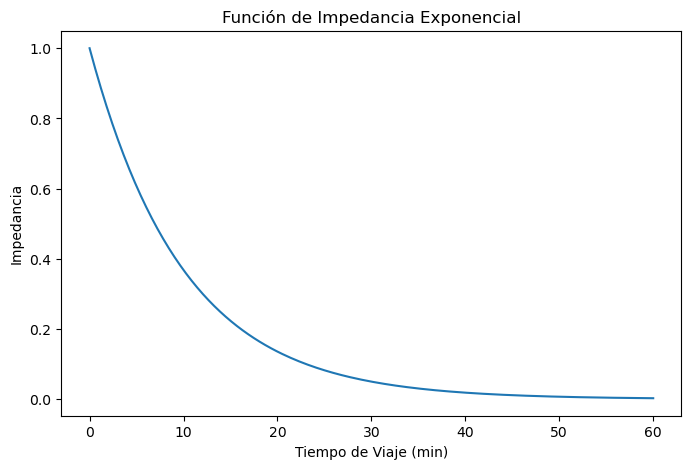

In [7]:
##impedance function

import matplotlib.pyplot as plt

def calcular_impedancia(costo_ij, phi):
    """
    crea una función de impedancia que decae exponencialmente con el costo (distancia/tiempo).
    """
    return np.exp(costo_ij*phi)

# graficar la función de impedancia
tiempos = np.linspace(0, 60, 200)  
phi = -0.1
impedancia_vals = calcular_impedancia(tiempos, phi)

plt.figure(figsize=(8,5))
plt.plot(tiempos, impedancia_vals)
plt.title("Función de Impedancia Exponencial")
plt.xlabel("Tiempo de Viaje (min)")
plt.ylabel("Impedancia")
plt.show()

### Building the Impedance Matrices $F_{i,j}^{m}$

With the decay function validated, we apply it elementwise to the full origin–destination cost matrices computed earlier — `drive_matrix` ($C_{i,j}^{drive}$) and `walk_matrix` ($C_{i,j}^{walk}$) — using `.map()` to vectorize `calcular_impedancia` across every cell pair.

This produces `impedance_auto` and `impedance_caminata`, the mode-specific impedance matrices $F_{i,j}^{drive}$ and $F_{i,j}^{walk}$, indexed identically to their source cost matrices. These are the direct inputs to the accessibility summation: $$acc_{i}^{m,p} = \sum_{j} N_{j}^{p} \cdot F_{i,j}^{m}$$ in the next step.

In [8]:
# aplicar la función de impedancia a cada matriz de costos
impedance_auto = drive_matrix.map(calcular_impedancia, phi=-0.5)
impedance_caminata = walk_matrix.map(calcular_impedancia, phi=-0.5)


In [9]:
# exportar impedancias (anexo)
# Export with rows/columns labelled by h3 id (in the current `celdas` order) so that
# downstream phases can align the matrices by h3 instead of relying on row position —
# the grid gets re-sorted by h3 later in the pipeline, which silently breaks any
# positional dot product against these matrices.
impedance_auto_export = impedance_auto.copy()
impedance_auto_export.index = celdas['h3'].values
impedance_auto_export.columns = celdas['h3'].values
impedance_auto_export.to_json("anexos/phase3/impedance_auto.json")

impedance_caminata_export = impedance_caminata.copy()
impedance_caminata_export.index = celdas['h3'].values
impedance_caminata_export.columns = celdas['h3'].values
impedance_caminata_export.to_json("anexos/phase3/impedance_caminata.json")

### Calculation - Gravitational Accessibility

Using the previously calculated impedance matrix 
$F_{i,j}^{m}$ 
and the variables of interest 
$N_{j}^{p}$
(e.g., land uses), we can calculate the accessibility for each cell and each variable of interest. Our resulting DataFrame will have new columns, such as `acc_drive_m2_comercio`, `acc_drive_m2_industria`, etc., representing accessibility from each cell to the sum of those land uses, penalized by distance/time.

In [10]:
# filtrar por variables y multiplicación matricial con .dot()
variables = ['m2_commercial', 'n_commercial',
             'm2_recreation_and_culture', 'n_recreation_and_culture',
             'm2_education', 'n_education',
             'm2_office', 'n_office',
             'n_residential', 'm2_residential',
             'n_industrial','m2_industrial',
             'n_civic','m2_civic',
             'n_transport','m2_transport',
             'n_health','m2_health',
             'n_paraderos']

accesibilidades_auto = impedance_auto.dot(celdas[variables])
accesibilidades_caminata = impedance_caminata.dot(celdas[variables])

# renombrar columnas
accesibilidades_auto.columns = [f"acc_auto_{col}" for col in accesibilidades_auto.columns]
accesibilidades_caminata.columns = [f"acc_caminata_{col}" for col in accesibilidades_caminata.columns]

# agregar geometría (positional concat is safe here: both sides are still in `celdas` order)
accesibilidades_auto = pd.concat(
    [celdas[['h3', 'geometry']].reset_index(drop=True),
     accesibilidades_auto.reset_index(drop=True)],
    axis=1
)
accesibilidades_caminata = pd.concat(
    [celdas[['h3', 'geometry']].reset_index(drop=True),
     accesibilidades_caminata.reset_index(drop=True)],
    axis=1
)


In [11]:
# QA: one accessibility row per cell, no duplicated h3 ids
print(f"cells: {len(celdas)}, auto rows: {len(accesibilidades_auto)}, walk rows: {len(accesibilidades_caminata)}")
print("duplicated h3 (auto, walk):", accesibilidades_auto['h3'].duplicated().sum(), accesibilidades_caminata['h3'].duplicated().sum())


cells: 650, auto rows: 650, walk rows: 650
duplicated h3 (auto, walk): 0 0


In [12]:
# visualizar accesibilidades in DRIVING and m2 of built area in RESIDENTIAL
#deduplicate columns
#accesibilidades_auto = accesibilidades_auto.loc[:, ~accesibilidades_auto.columns.duplicated()]

accesibilidades_auto.explore(column='acc_auto_n_residential', scheme='NaturalBreaks', k=10)

#accesibilidades_auto.sort_values(by="acc_auto_m2_education", ascending=False).head(10)

In [13]:
accesibilidades_caminata.explore(column='acc_caminata_n_paraderos', scheme='NaturalBreaks', k=10)

### Combining modes into the estimation grid

The auto and walking accessibility tables are merged on `h3` into a single table (`accesibilidades_total`) that feeds the price and choice model estimation. Note that pandas sorts the join key on an outer merge, so from this point on the grid is in **h3-sorted order** — alignment with the impedance matrices must always be done by h3 label, never by row position.


In [14]:
# combine both modes into a single estimation table.
# NOTE: how='outer' SORTS the result by h3 — every downstream grid
# (celdas_estimacion, celdas_predict) is therefore in h3-sorted order, which no
# longer matches the positional order of the impedance matrices. That is why the
# impedance exports in this notebook carry h3 row/column labels.
accesibilidades_total = accesibilidades_auto.merge(
    accesibilidades_caminata,
    on="h3",
    how="outer",
    suffixes=("_auto", "_cam")
).drop(columns=['geometry_auto'])


In [15]:
# exportar los GeoDataFrame de accesibilidades a archivos GeoJSON
accesibilidades_auto.to_file("anexos/phase3/celdas_accesibilidades_auto.geojson")
accesibilidades_caminata.to_file("anexos/phase3/celdas_accesibilidades_caminata.geojson")
accesibilidades_total.to_file("anexos/phase3/celdas_accessibilidades_estimacion.geojson")

# add structural variables to celdas_simulacion
celdas_simulacion = accesibilidades_total.merge(
    celdas.drop(columns="geometry"), on="h3", how="left"
)

celdas_simulacion.to_file("anexos/phase3/celdas_estimacion.geojson")
